# 14 · Stress Cycles, Seasonality & Age-Period-Cohort (`14_cycle_and_benchmarks.py`)

Portfolio risk teams separate *structural underwriting risk* from three calendar effects: macroeconomic stress episodes (`cycle_mart`), predictable calendar-month seasonality (`seasonality_mart`), and Age-Period-Cohort dynamics (`apc_mart`). Here we verify all three benchmark marts read-only and visualize the monthly seasonal rhythm of defaults versus payoffs.

<div style="background:#FFFFFF; border:1px solid #E5E7EB; border-radius:10px; padding:14px; margin:8px 0;">
<div style="font-family:Segoe UI,Arial,sans-serif; font-size:13px; font-weight:700; color:#051C2C; margin-bottom:8px;">Stress Cycles, Calendar Seasonality &amp; APC Decomposition</div>
<svg viewBox="0 0 920 110" width="100%" xmlns="http://www.w3.org/2000/svg">
<defs><marker id="arr" viewBox="0 0 10 10" refX="8" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M 0 1 L 10 5 L 0 9 z" fill="#2251FF"/></marker></defs>
<rect x="20" y="18" width="170" height="68" rx="8" fill="#051C2C" stroke="#051C2C" stroke-width="1.5"/>
<text x="105.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Stress Episode Flags</text>
<text x="105.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">m2.cycle_mart (mean + 1 SD)</text>
<line x1="194" y1="52" x2="252" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="256" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="341.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">12-Month Rhythm</text>
<text x="341.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.seasonality_mart</text>
<line x1="430" y1="52" x2="488" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="492" y="18" width="170" height="68" rx="8" fill="#F8FAFC" stroke="#2251FF" stroke-width="1.5"/>
<text x="577.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#051C2C">Age-Period-Cohort</text>
<text x="577.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#475569">m2.apc_mart (age x era)</text>
<line x1="666" y1="52" x2="724" y2="52" stroke="#2251FF" stroke-width="2" marker-end="url(#arr)"/>
<rect x="728" y="18" width="170" height="68" rx="8" fill="#2251FF" stroke="#2251FF" stroke-width="1.5"/>
<text x="813.0" y="46" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="12" font-weight="700" fill="#FFFFFF">Benchmark Checks</text>
<text x="813.0" y="66" text-anchor="middle" font-family="Segoe UI,Arial,sans-serif" font-size="10.5" fill="#CBD5E1">Seasonal mean ~= 1.0 check</text>
</svg></div>

We load our read-only connection and inspect every detected stress episode in `m2.cycle_mart` along with seasonal factor normalization checks across `m2.seasonality_mart`.

In [1]:
# Load path, DuckDB, pandas, I/O, and inline chart display utilities
# Import standard libraries to inspect saved marts read-only and render 300 dpi figures inline
import io
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from IPython.display import Image, display

# Locate residential_mortgage/ root and attach module2_sample.duckdb strictly READ_ONLY
# Walk upward until reaching residential_mortgage/, then open an in-memory DuckDB connection
PACKAGE_ROOT = Path.cwd()
while PACKAGE_ROOT.name != "residential_mortgage" and PACKAGE_ROOT != PACKAGE_ROOT.parent:
    PACKAGE_ROOT = PACKAGE_ROOT.parent
if PACKAGE_ROOT.name != "residential_mortgage":
    PACKAGE_ROOT = Path(r"E:\Repos\V4_bank-credit-risk-platform\residential_mortgage")

FIXED_M2_DB = PACKAGE_ROOT / "00_data/processed/module_outputs/02_portfolio_analytics/sample/module2_sample.duckdb"
con = duckdb.connect(":memory:")
con.execute(f"ATTACH '{FIXED_M2_DB.as_posix()}' AS m2 (READ_ONLY)")

# Inspect stress episodes where quarterly default rate exceeded long-run mean + 1 SD
# Query all rows from m2.cycle_mart ordered chronologically by start_quarter
display(con.execute("""
    SELECT cycle_name, start_quarter, peak_quarter, end_quarter, duration_quarters,
           round(peak_rate * 100, 2) AS peak_rate_pct, recovery_halflife_quarters,
           round(benchmark_lra_mean * 100, 2) AS lra_mean_pct
    FROM m2.cycle_mart
    ORDER BY start_quarter
""").fetchdf())

# Verify seasonal indices average near 1.0 across all 12 calendar months
# Aggregate mean seasonal_factor and peak calendar month per metric in m2.seasonality_mart
con.execute("""
    SELECT metric_name, count(*)::BIGINT AS months,
           round(avg(seasonal_factor), 3) AS mean_factor,
           arg_max(calendar_month, seasonal_factor) AS peak_month,
           round(max(seasonal_factor), 3) AS peak_factor
    FROM m2.seasonality_mart
    GROUP BY metric_name
    ORDER BY metric_name
""").fetchdf()

,cycle_name,start_quarter,peak_quarter,end_quarter,duration_quarters,peak_rate_pct,recovery_halflife_quarters,lra_mean_pct
0,ep_1_2008Q4,2008Q4,2009Q2,2010Q1,6,4.81,3.0,0.93
1,ep_2_2010Q3,2010Q3,2010Q3,2011Q1,3,2.63,3.0,0.93
2,ep_3_2011Q4,2011Q4,2012Q1,2012Q1,2,2.76,1.0,0.93
3,ep_4_2020Q4,2020Q4,2020Q4,2021Q1,2,6.30,1.0,0.93


,metric_name,months,mean_factor,peak_month,peak_factor
0,monthly_cure_hazard,12,1.001,12,1.346
1,monthly_default_hazard,12,0.998,10,1.579
2,monthly_prepay_hazard,12,1.000,8,1.099


Next we inspect `m2.apc_mart` across loan age buckets so we can see how annualized default and prepayment hazards evolve with loan seasoning.

In [2]:
# Summarize annualized default and prepayment hazards by loan age bucket in apc_mart
# Aggregate m2.apc_mart exposure, defaults, and payoffs per age_bucket cleanly
con.execute("""
    SELECT age_bucket,
           sum(loan_months_at_risk)::BIGINT AS loan_months,
           sum(defaults)::BIGINT AS defaults,
           sum(payoffs)::BIGINT AS payoffs,
           round(100.0 * sum(defaults) * 12.0 / NULLIF(sum(loan_months_at_risk), 0), 3) AS ann_default_pct,
           round(100.0 * sum(payoffs) * 12.0 / NULLIF(sum(loan_months_at_risk), 0), 2) AS ann_prepay_pct
    FROM m2.apc_mart
    GROUP BY age_bucket
    ORDER BY age_bucket
""").fetchdf()

,age_bucket,loan_months,defaults,payoffs,ann_default_pct,ann_prepay_pct
0,00_11m,196249,65,1732,0.397,10.59
1,12_23m,165378,121,2500,0.878,18.14
2,24_35m,135020,114,1828,1.013,16.25
3,36_59m,197025,160,2295,0.974,13.98
4,60m+,252651,221,3675,1.050,17.45


Finally we plot the 12-month seasonal profile comparing relative monthly default hazard against prepayment and cure hazards at 300 dpi.

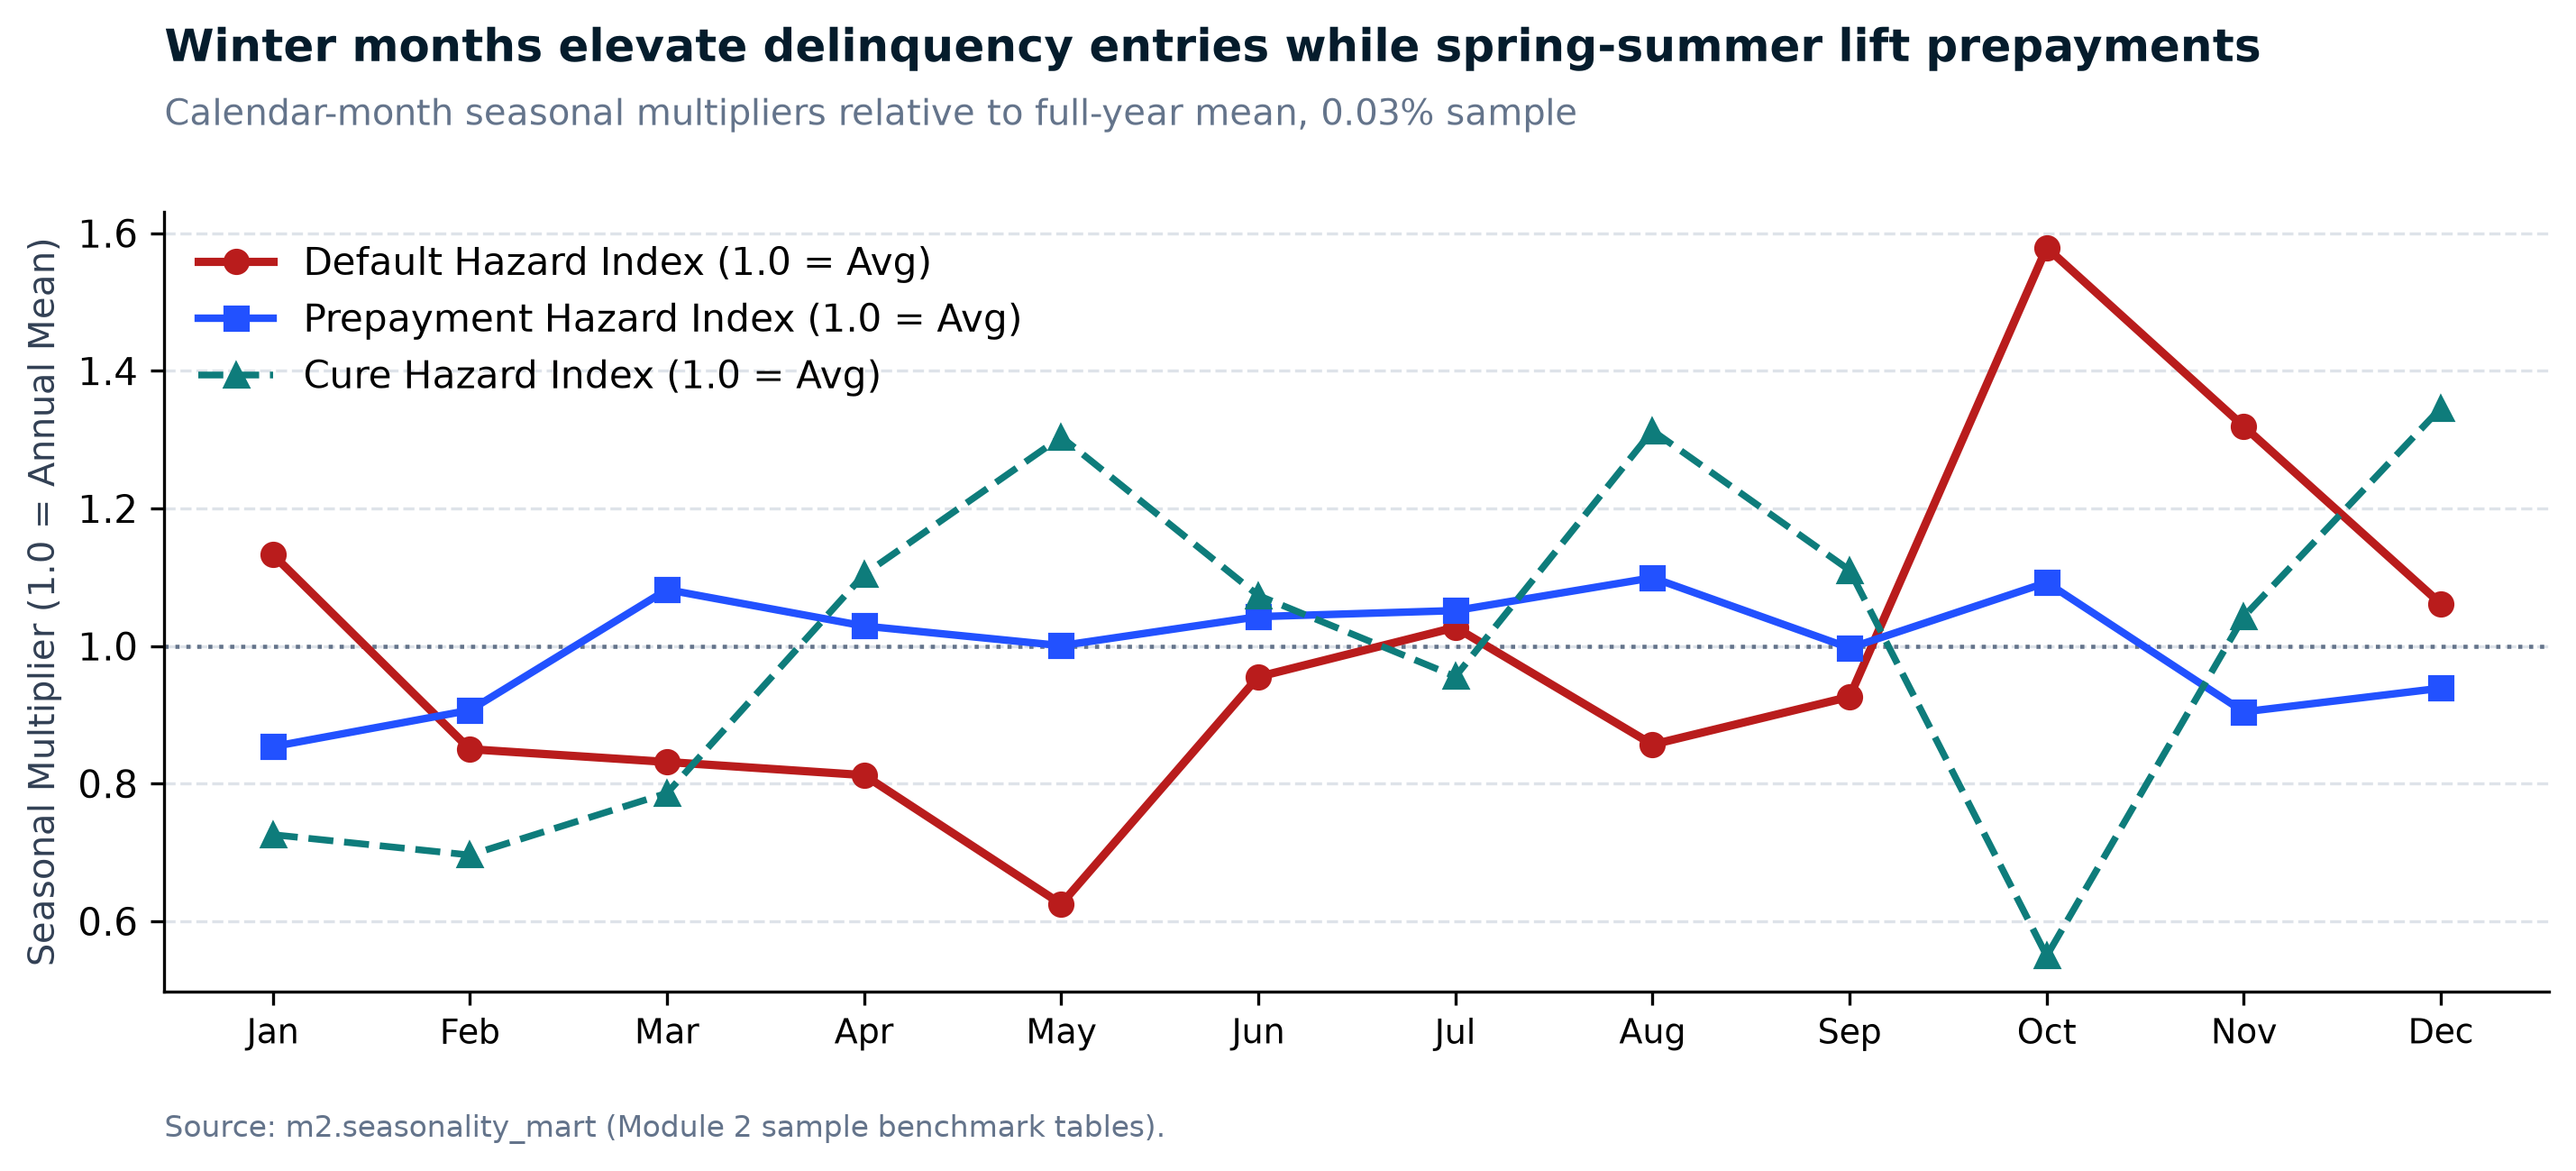

In [3]:
# Plot calendar-month seasonal factors for default, prepayment, and cure hazards
# Pivot m2.seasonality_mart by calendar_month and render inline at 300 dpi via BytesIO
seas = con.execute("""
    SELECT calendar_month, metric_name, seasonal_factor
    FROM m2.seasonality_mart
    WHERE metric_name IN ('monthly_default_hazard', 'monthly_prepay_hazard', 'monthly_cure_hazard')
    ORDER BY calendar_month
""").fetchdf().pivot(index="calendar_month", columns="metric_name", values="seasonal_factor")

fig, ax = plt.subplots(figsize=(9.8, 4.3), dpi=300, facecolor="#FFFFFF")
ax.set_facecolor("#FFFFFF")
ax.plot(seas.index, seas["monthly_default_hazard"], marker="o", linewidth=2.2, color="#B91C1C", label="Default Hazard Index (1.0 = Avg)", zorder=3)
ax.plot(seas.index, seas["monthly_prepay_hazard"], marker="s", linewidth=2.0, color="#2251FF", label="Prepayment Hazard Index (1.0 = Avg)", zorder=3)
ax.plot(seas.index, seas["monthly_cure_hazard"], marker="^", linewidth=1.8, linestyle="--", color="#0E7C7B", label="Cure Hazard Index (1.0 = Avg)", zorder=3)
ax.axhline(1.0, color="#64748B", linestyle=":", linewidth=1.1)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], fontsize=9)
ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8", zorder=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_ylabel("Seasonal Multiplier (1.0 = Annual Mean)", fontsize=9.5, color="#334155")
ax.legend(frameon=False, loc="upper left")
fig.text(0.07, 0.94, "Winter months elevate delinquency entries while spring-summer lift prepayments", fontsize=12, fontweight="bold", color="#051C2C")
fig.text(0.07, 0.885, "Calendar-month seasonal multipliers relative to full-year mean, 0.03% sample", fontsize=9.5, color="#64748B")
fig.text(0.07, 0.015, "Source: m2.seasonality_mart (Module 2 sample benchmark tables).", fontsize=8, color="#64748B")
plt.subplots_adjust(left=0.07, right=0.97, top=0.81, bottom=0.14)
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=300, bbox_inches="tight", facecolor="#FFFFFF")
plt.close(fig)
display(Image(data=buf.getvalue()))

# Close the in-memory DuckDB connection cleanly
# Release the attached read-only sample DB handle
con.close()